# Практическое задание № 1. Классификация


# Распознавание активности человека на основе данных с мобильных сенсоров

Необходимо по данным с мобильных сенсоров при помощи прикладных алгоритмов машинного обучения предсказать активность человека по шести классам движений:
* Движется по прямой
* Движется вверх (например, движение по лестнице вверх)
* Движется вниз (например, движение по лестнице вниз)
* Сидит
* Стоит
* Лежит

## Сведения о наборе данных
Набор данных содержит записи датчиков со сматфонов (акселерометр и гироскоп с частотой дискретизации 50 Гц) от 30 участников, выполняющих следующие действия: ходьба, ходьба по лестнице, ходьба по лестнице, сидение, стояние и лежание. Данные были предварительно обработаны при помощи фильтров шума. Набор данных представлен Хорхе Л. Рейес-Ортисом.

Признаки были извлечены из 3-х осевых необработанных сигналов акселерометра и гироскопа tAcc-XYZ и tGyro-XYZ. Эти сигналы были сняты с постоянной частотой 50 Гц. Затем были отфильтрованны с помощью медианного фильтра и низкочастотного фильтра Баттерворта 3-го порядка с частотой 20 Гц для удаления шумов. Аналогичным образом сигнал ускорения был разделен на сигналы ускорения тела и гравитации (`tBodyAcc-XYZ` и `tGravityAcc-XYZ`) с помощью другого низкочастотного фильтра Баттерворта с угловой частотой 0,3 Гц. Линейное ускорение тела и угловая скорость были использованы для получения сигналов "рывка" — (`tBodyAccJerk-XYZ` и `tBodyGyroJerk-XYZ`). Также величина этих трехмерных сигналов была расчитана с использованием евклидовой нормы — (`tBodyAccMag`, `tGravityAccMag`, `tBodyAccJerkMag`, `tBodyGyroMag`, `tBodyGyroJerkMag`). 

Наконец, к некоторым из этих сигналов было применено быстрое преобразование Фурье (БПФ), в результате чего получились `fBodyAcc-XYZ`, `fBodyAccJerk-XYZ`, `fBodyGyro-XYZ`, `fBodyAccJerkMag`, `fBodyGyroMag`, `fBodyGyroJerkMag`. (Обратите внимание на "f" для обозначения сигналов в частотной области). 

Набор переменных, которые были оценены по этим сигналам, следующий: 
* mean(): Среднее значение
* std(): Стандартное отклонение
* mad(): Среднее абсолютное отклонение 
* max(): Наибольшее значение в массиве
* min(): Наименьшее значение в массиве
* sma(): Область величины сигнала
* energy(): Мера энергии. Сумма квадратов, деленная на количество значений. 
* iqr(): Интерквартильный размах 
* entropy(): Энтропия сигнала
* arCoeff(): Коэффициенты авторегрессии с порядком Burg, равным 4
* correlation(): коэффициент корреляции между двумя сигналами
* maxInds(): индекс частотной составляющей с наибольшей величиной
* meanFreq(): средневзвешенное значение частотных компонент для получения средней частоты
* skewness(): перекос сигнала в частотной области 
* kurtosis(): эксцесс сигнала в частотной области 
* bandsEnergy(): Энергия частотного интервала в пределах 64 бинов БПФ каждого окна.
* angle(): Угол между векторами.
## Импорт библиотек
Первым делом импортируем необходимые библиотеки для работы с данными:

In [2]:
import os
import numpy as np
import pandas as pd

## Считываем набор данных

В прикладных задачах машинного обучения очень важен процесс извлечения признаков (feature extraction), в ходе которого данные интерпретируются в информативные признаки. Также этот процесс может называться проектирование признаков (feature engineering), это весьма трудоемкая и творческая задача. В рамках работы мы опустим эту часть и воспользуемся предобработанными данными. 

In [5]:
def read_data(path, filename):
    return pd.read_csv(os.path.join(path, filename))

df = read_data('', 'train.csv')
df.head()

,tBodyAcc-mean()-X,tBodyAcc-mean()-Y,tBodyAcc-mean()-Z,tBodyAcc-std()-X,tBodyAcc-std()-Y,tBodyAcc-std()-Z,tBodyAcc-mad()-X,tBodyAcc-mad()-Y,tBodyAcc-mad()-Z,tBodyAcc-max()-X,...,fBodyBodyGyroJerkMag-kurtosis(),"angle(tBodyAccMean,gravity)","angle(tBodyAccJerkMean),gravityMean)","angle(tBodyGyroMean,gravityMean)","angle(tBodyGyroJerkMean,gravityMean)","angle(X,gravityMean)","angle(Y,gravityMean)","angle(Z,gravityMean)",subject,Activity
0,0.288585,-0.020294,-0.132905,-0.995279,-0.983111,-0.913526,-0.995112,-0.983185,-0.923527,-0.934724,...,-0.710304,-0.112754,0.030400,-0.464761,-0.018446,-0.841247,0.179941,-0.058627,1,STANDING
1,0.278419,-0.016411,-0.123520,-0.998245,-0.975300,-0.960322,-0.998807,-0.974914,-0.957686,-0.943068,...,-0.861499,0.053477,-0.007435,-0.732626,0.703511,-0.844788,0.180289,-0.054317,1,STANDING
2,0.279653,-0.019467,-0.113462,-0.995380,-0.967187,-0.978944,-0.996520,-0.963668,-0.977469,-0.938692,...,-0.760104,-0.118559,0.177899,0.100699,0.808529,-0.848933,0.180637,-0.049118,1,STANDING
3,0.279174,-0.026201,-0.123283,-0.996091,-0.983403,-0.990675,-0.997099,-0.982750,-0.989302,-0.938692,...,-0.482845,-0.036788,-0.012892,0.640011,-0.485366,-0.848649,0.181935,-0.047663,1,STANDING
4,0.276629,-0.016570,-0.115362,-0.998139,-0.980817,-0.990482,-0.998321,-0.979672,-0.990441,-0.942469,...,-0.699205,0.123320,0.122542,0.693578,-0.615971,-0.847865,0.185151,-0.043892,1,STANDING


Теперь, загрузим полный набор данных и сохранить его под следующими четырьмя переменными:

* `train_X`: признаки, используемые для обучения модели
* `train_y`: метки, используемые для обучения модели
* `test_X`: признаки, используемые для проверки модели
* `test_y`: метки, используемые для проверки модели

In [6]:
def load_dataset(label_dict):
    train_X = read_data('', 'train.csv').values[:,:-2]
    train_y = read_data('', 'train.csv')['Activity']
    train_y = train_y.map(label_dict).values
    test_X = read_data('', 'test.csv').values[:,:-2]
    test_y = read_data('', 'test.csv')
    test_y = test_y['Activity'].map(label_dict).values
    return(train_X, train_y, test_X, test_y)
label_dict = {'WALKING':0, 'WALKING_UPSTAIRS':1, 'WALKING_DOWNSTAIRS':2, 'SITTING':3, 'STANDING':4, 'LAYING':5}
train_X, train_y, test_X, test_y = load_dataset(label_dict)

## Выбор модели

Импортируйте выбранную вами модель из библиотеки `sklearn` и инициализируйте её в объект `model`:

Также необходимо выбрать **несколько** моделей ML для сравнения полученных результатов.

In [7]:

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier

models = {
    # Logistic Regression: меняется C
    "LogReg C=0.1": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=0.1,
            max_iter=3000,
            random_state=42
        )
    ),

    "LogReg C=1": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=1,
            max_iter=3000,
            random_state=42
        )
    ),

    "LogReg C=10": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            C=10,
            max_iter=3000,
            random_state=42
        )
    ),

    # SVC: меняются kernel и C
    "SVC linear C=1": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=1
        )
    ),

    "SVC RBF C=1": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=1,
            gamma="scale"
        )
    ),

    "SVC RBF C=10": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale"
        )
    ),

    # Random Forest: меняются n_estimators и max_depth
    "Random Forest 100 depth=10": RandomForestClassifier(
        n_estimators=100,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest 300 depth=10": RandomForestClassifier(
        n_estimators=300,
        max_depth=10,
        random_state=42,
        n_jobs=-1
    ),

    "Random Forest 300 depth=None": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )
}

Опишите вашу мотивацию по выбору модели. Какие гиперпараметры есть у выбранной вами модели? За что они отвечают? На что влияют?

### Мотивация выбора моделей

Для сравнения выбраны Logistic Regression, SVC и Random Forest.

Logistic Regression используется как быстрая линейная базовая модель.
Она подходит для данных с большим количеством числовых признаков.

SVC выбран из-за способности строить как линейные, так и нелинейные
разделяющие границы. Это позволяет сравнить ядра linear и RBF.

Random Forest представляет ансамблевый алгоритм на основе деревьев решений.
Он способен находить нелинейные зависимости и не требует масштабирования
признаков.

Основной гиперпараметр Logistic Regression - C. Это величина, обратная
силе регуляризации. Маленькое C усиливает регуляризацию и упрощает модель,
а большое C позволяет модели сильнее подстраиваться под обучающие данные.

У SVC параметр C определяет штраф за ошибки классификации, kernel выбирает
вид разделяющей границы, а gamma определяет радиус влияния отдельных
объектов для ядра RBF.

У Random Forest параметр n_estimators задаёт количество деревьев, а
max_depth ограничивает их глубину. Увеличение количества деревьев обычно
делает результат стабильнее, а слишком большая глубина может привести
к переобучению.

## Обучение модели

Обучите модель, используя признаки из обучающего набора (`train_X`) и метки в качестве базовой истины (`train_y`).

In [8]:
import time

training_times = {}

for model_name, model in models.items():
    print(f"Обучение модели: {model_name}")
    start_time = time.perf_counter()
    model.fit(train_X, train_y)
    training_time = time.perf_counter() - start_time
    training_times[model_name] = training_time

print("Все модели обучены")

Обучение модели: LogReg C=0.1
Обучение модели: LogReg C=1
Обучение модели: LogReg C=10
Обучение модели: SVC linear C=1
Обучение модели: SVC RBF C=1
Обучение модели: SVC RBF C=10
Обучение модели: Random Forest 100 depth=10
Обучение модели: Random Forest 300 depth=10
Обучение модели: Random Forest 300 depth=None
Все модели обучены


## Оценка модели
Используйте обученную модель для прогнозирования активности движения, используя признаки из тестового набора (`test_X`). Прогнозы сохраните в списке `yhat`.

In [9]:
import time

predictions = {}
prediction_times = {}

for model_name, model in models.items():
    print(f"Получение предсказаний: {model_name}")

    start_time = time.perf_counter()

    yhat = model.predict(test_X)

    prediction_time = time.perf_counter() - start_time

    predictions[model_name] = yhat
    prediction_times[model_name] = prediction_time
    print( model_name, prediction_time)


print("Предсказания всех моделей получены")

Получение предсказаний: LogReg C=0.1
LogReg C=0.1 0.06002649990841746
Получение предсказаний: LogReg C=1
LogReg C=1 0.058838299941271544
Получение предсказаний: LogReg C=10
LogReg C=10 0.05957569996826351
Получение предсказаний: SVC linear C=1
SVC linear C=1 0.46120529994368553
Получение предсказаний: SVC RBF C=1
SVC RBF C=1 3.0923486000392586
Получение предсказаний: SVC RBF C=10
SVC RBF C=10 2.473559700185433
Получение предсказаний: Random Forest 100 depth=10
Random Forest 100 depth=10 0.10588239994831383
Получение предсказаний: Random Forest 300 depth=10
Random Forest 300 depth=10 0.18877099989913404
Получение предсказаний: Random Forest 300 depth=None
Random Forest 300 depth=None 0.19142229994758964
Предсказания всех моделей получены


In [10]:
import pandas as pd

from sklearn.metrics import classification_report

target_names = [
    "Walking",
    "Walking Upstairs",
    "Walking Downstairs",
    "Sitting",
    "Standing",
    "Laying"
]

class_labels = [0, 1, 2, 3, 4, 5]

results = []
classification_reports = {}

for model_name, yhat in predictions.items():
    # Отчёт в виде словаря для создания общей таблицы
    report = classification_report(
        test_y,
        yhat,
        labels=class_labels,
        target_names=target_names,
        output_dict=True,
        zero_division=0
    )

    classification_reports[model_name] = report

    results.append({
        "model": model_name,
        "accuracy": report["accuracy"],
        "precision_macro": report["macro avg"]["precision"],
        "recall_macro": report["macro avg"]["recall"],
        "f1_macro": report["macro avg"]["f1-score"],
        "training_time_sec": training_times[model_name],
        "prediction_time_sec": prediction_times[model_name]
    })

    # Подробный текстовый отчёт для каждой модели
    print("=" * 70)
    print(f"Модель: {model_name}")
    print("=" * 70)

    print(
        classification_report(
            test_y,
            yhat,
            labels=class_labels,
            target_names=target_names,
            digits=4,
            zero_division=0
        )
    )

# Общая сравнительная таблица
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="f1_macro",
    ascending=False
).reset_index(drop=True)

display(
    results_df.style.format({
        "accuracy": "{:.4f}",
        "precision_macro": "{:.4f}",
        "recall_macro": "{:.4f}",
        "f1_macro": "{:.4f}",
        "training_time_sec": "{:.2f}",
        "prediction_time_sec": "{:.4f}"
    })
)

Модель: LogReg C=0.1
                    precision    recall  f1-score   support

           Walking     0.9408    0.9940    0.9667       496
  Walking Upstairs     0.9530    0.9469    0.9499       471
Walking Downstairs     0.9899    0.9381    0.9633       420
           Sitting     0.9577    0.8758    0.9149       491
          Standing     0.8769    0.9643    0.9185       532
            Laying     1.0000    0.9739    0.9868       537

          accuracy                         0.9498      2947
         macro avg     0.9531    0.9488    0.9500      2947
      weighted avg     0.9518    0.9498    0.9499      2947

Модель: LogReg C=1
                    precision    recall  f1-score   support

           Walking     0.9444    0.9940    0.9686       496
  Walking Upstairs     0.9572    0.9490    0.9531       471
Walking Downstairs     0.9899    0.9381    0.9633       420
           Sitting     0.9663    0.8758    0.9188       491
          Standing     0.8898    0.9718    0.9290       

,model,accuracy,precision_macro,recall_macro,f1_macro,training_time_sec,prediction_time_sec
0,SVC linear C=1,0.9610,0.9629,0.9600,0.9608,1.54,0.4612
1,LogReg C=1,0.9549,0.9576,0.9535,0.9547,3.53,0.0588
2,SVC RBF C=10,0.9549,0.9559,0.9531,0.9540,2.34,2.4736
3,LogReg C=10,0.9525,0.9542,0.9509,0.9518,4.14,0.0596
4,SVC RBF C=1,0.9522,0.9528,0.9508,0.9515,2.58,3.0923
5,LogReg C=0.1,0.9498,0.9531,0.9488,0.9500,1.70,0.0600
6,Random Forest 300 depth=None,0.9287,0.9301,0.9258,0.9271,4.87,0.1914
7,Random Forest 300 depth=10,0.9230,0.9249,0.9194,0.9208,4.19,0.1888
8,Random Forest 100 depth=10,0.9206,0.9229,0.9165,0.9181,1.61,0.1059


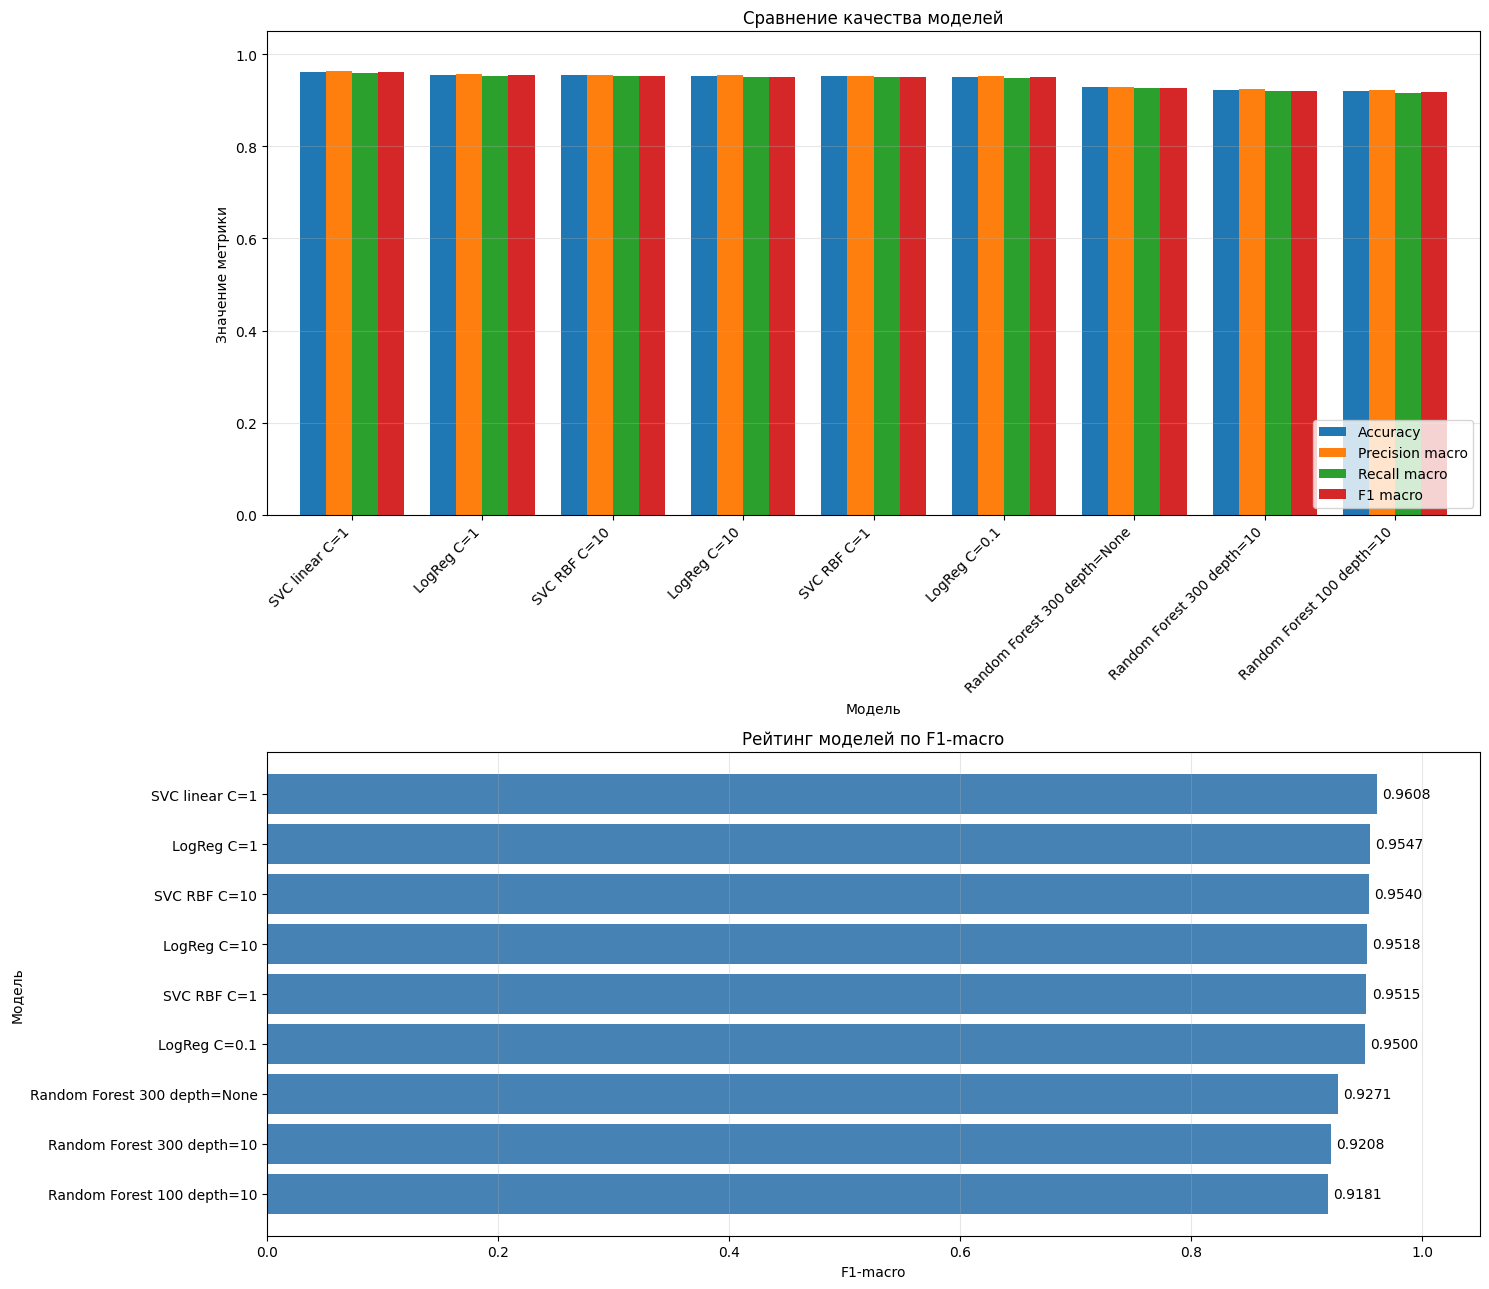

In [11]:
#Результаты сравнения




import matplotlib.pyplot as plt

metrics = [
    "accuracy",
    "precision_macro",
    "recall_macro",
    "f1_macro"
]

metric_labels = {
    "accuracy": "Accuracy",
    "precision_macro": "Precision macro",
    "recall_macro": "Recall macro",
    "f1_macro": "F1 macro"
}

# Подготовка данных
plot_data = (
    results_df
    .set_index("model")[metrics]
    .rename(columns=metric_labels)
)

fig, axes = plt.subplots(
    nrows=2,
    ncols=1,
    figsize=(15, 13)
)

# Общий график всех метрик
plot_data.plot(
    kind="bar",
    ax=axes[0],
    width=0.8
)

axes[0].set_title("Сравнение качества моделей")
axes[0].set_xlabel("Модель")
axes[0].set_ylabel("Значение метрики")
axes[0].set_ylim(0, 1.05)
axes[0].grid(axis="y", alpha=0.3)
axes[0].tick_params(axis="x", rotation=45)

for label in axes[0].get_xticklabels():
    label.set_horizontalalignment("right")

axes[0].legend(loc="lower right")

# Рейтинг моделей по F1-macro
f1_results = results_df.sort_values(
    by="f1_macro",
    ascending=True
)

bars = axes[1].barh(
    f1_results["model"],
    f1_results["f1_macro"],
    color="steelblue"
)

axes[1].set_title("Рейтинг моделей по F1-macro")
axes[1].set_xlabel("F1-macro")
axes[1].set_ylabel("Модель")
axes[1].set_xlim(0, 1.05)
axes[1].grid(axis="x", alpha=0.3)

# Подписи значений на столбцах
axes[1].bar_label(
    bars,
    fmt="%.4f",
    padding=4
)

plt.tight_layout()
plt.show()

## Задание


Выведите отчет о классификации, сравнив предсказания (`yhat`) с базовой истиной (`test_y`).

В чем разница между показателями `precision` и `recall`? Что такое показатель `F1`?

Используйте вариации нескольких моделей с разными гиперпараметрами. Сравните полученный результат (визуализируйте полученный результат).

Что такое гиперпараметры модели машинного обучения (МО)?

Опишите влияние гиперпараметров в выбранных вами моделях МО.

### Метрики качества

Precision показывает, какая доля объектов, отнесённых моделью к определённому
классу, действительно относится к этому классу:

precision = TP / (TP + FP).

Recall показывает, какую долю объектов соответствующего класса модель смогла
обнаружить:

recall = TP / (TP + FN).

F1 является гармоническим средним precision и recall:

F1 = 2 × precision × recall / (precision + recall).

### Вывод

Лучший результат показала модель SVC с линейным ядром и C=1:
accuracy составила 0.9610, а F1-macro - 0.9608.

Для Logistic Regression лучший результат получен при C=1. Увеличение C до 10
не улучшило качество, поэтому дальнейшее ослабление регуляризации оказалось
неэффективным.

Для SVC увеличение C у ядра RBF улучшило F1-macro с 0.9515 до 0.9540,
однако линейное ядро всё равно показало лучший результат.

У Random Forest увеличение количества и глубины деревьев повысило F1-macro
с 0.9181 до 0.9271, но результаты остались ниже, чем у линейных моделей.